In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from google.colab import files

uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [2]:
df = pd.read_csv('Dataset.csv')

print("Dataset Shape:", df.shape)
print(df[['title', 'country', 'type']].head(10))

Dataset Shape: (8790, 10)
                              title         country     type
0              Dick Johnson Is Dead   United States    Movie
1                         Ganglands          France  TV Show
2                     Midnight Mass   United States  TV Show
3  Confessions of an Invisible Girl          Brazil    Movie
4                           Sankofa   United States    Movie
5     The Great British Baking Show  United Kingdom  TV Show
6                      The Starling   United States    Movie
7   Motu Patlu in the Game of Zones           India    Movie
8                      Je Suis Karl         Germany    Movie
9          Motu Patlu in Wonderland           India    Movie


In [3]:
# Country Data Inspection

print("Missing Country Values:")
print(df['country'].isnull().sum())

print("\nUnique Countries:")
print(df['country'].nunique())

print("\nSample Country Values:")
print(df['country'].dropna().head(20))

Missing Country Values:
0

Unique Countries:
86

Sample Country Values:
0      United States
1             France
2      United States
3             Brazil
4      United States
5     United Kingdom
6      United States
7              India
8            Germany
9              India
10             India
11             India
12          Pakistan
13     United States
14     United States
15     United States
16     United States
17          Pakistan
18          Pakistan
19     United States
Name: country, dtype: object


In [4]:
# Remove rows with missing country values
country_df = df.dropna(subset=['country']).copy()

# Split multiple countries into separate rows
country_df['country'] = country_df['country'].str.split(',')

# Expand countries into individual rows
country_df = country_df.explode('country')

# Remove extra spaces
country_df['country'] = country_df['country'].str.strip()

# Remove empty country values
country_df = country_df[country_df['country'] != '']

print("Country Data Prepared Successfully!")
print(country_df[['title', 'country', 'type']].head(15))

Country Data Prepared Successfully!
                               title         country     type
0               Dick Johnson Is Dead   United States    Movie
1                          Ganglands          France  TV Show
2                      Midnight Mass   United States  TV Show
3   Confessions of an Invisible Girl          Brazil    Movie
4                            Sankofa   United States    Movie
5      The Great British Baking Show  United Kingdom  TV Show
6                       The Starling   United States    Movie
7    Motu Patlu in the Game of Zones           India    Movie
8                       Je Suis Karl         Germany    Movie
9           Motu Patlu in Wonderland           India    Movie
10    Motu Patlu: Deep Sea Adventure           India    Movie
11          Motu Patlu: Mission Moon           India    Movie
12                  99 Songs (Tamil)        Pakistan    Movie
13       Bridgerton - The Afterparty   United States    Movie
14     Bling Empire - The Afterpar

In [5]:
# Top 10 Countries by Content Count

top_countries = country_df['country'].value_counts().head(10)

print("Top 10 Netflix Content-Producing Countries:")
print(top_countries)

Top 10 Netflix Content-Producing Countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


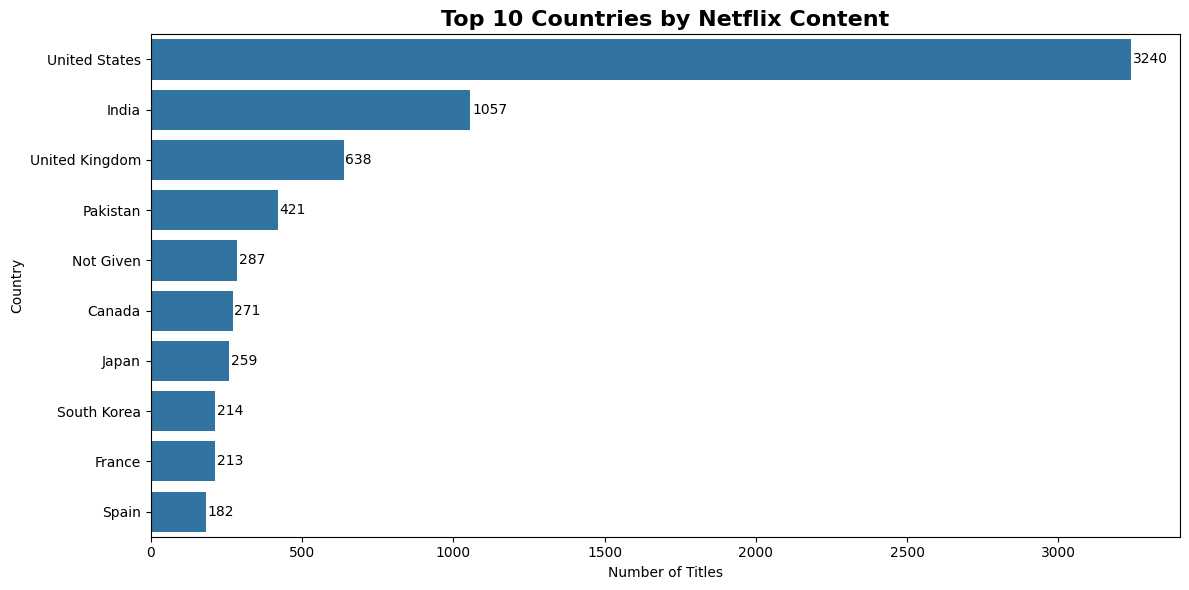

In [6]:

# Top 10 Countries - Bar Chart

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Content",
          fontsize=16, fontweight='bold')

plt.xlabel("Number of Titles")
plt.ylabel("Country")

for i, value in enumerate(top_countries.values):
    plt.text(value + 5, i, str(value), va='center')

plt.tight_layout()
plt.savefig("top_10_countries.png", dpi=300)
plt.show()


In [7]:

# Calculate Country Contribution

total_country_records = country_df['country'].count()

country_contribution = (
    country_df['country'].value_counts()
    .head(10)
    .to_frame(name='Content_Count')
)

country_contribution['Percentage'] = (
    country_contribution['Content_Count']
    / total_country_records * 100
)

print("Country-wise Market Contribution")
display(country_contribution.round(2))


Country-wise Market Contribution


,Content_Count,Percentage
country,,
United States,3240,36.86
India,1057,12.03
United Kingdom,638,7.26
Pakistan,421,4.79
Not Given,287,3.27
Canada,271,3.08
Japan,259,2.95
South Korea,214,2.43
France,213,2.42


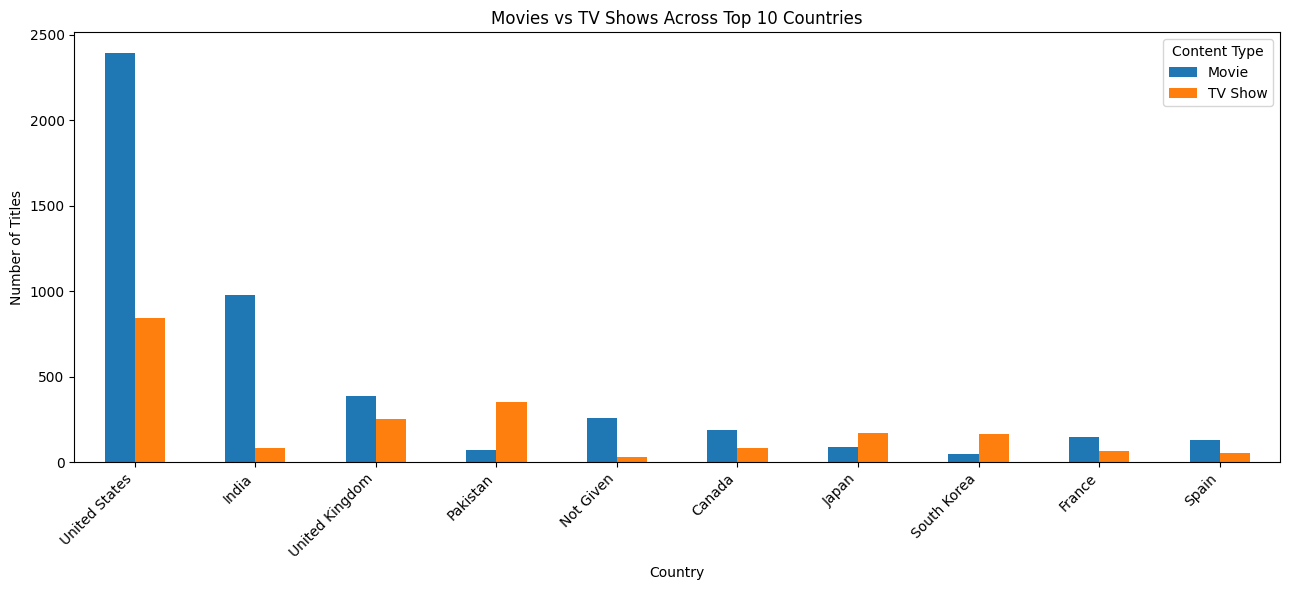

In [8]:

# Compare Movies and TV Shows across Top 10 Countries

country_type = pd.crosstab(
    country_df['country'],
    country_df['type']
)

top_10_type = country_type.loc[
    top_countries.index
]

top_10_type.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title("Movies vs TV Shows Across Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig("country_content_comparison.png", dpi=300)
plt.show()


In [9]:

# Business Insights and Market Recommendations

print("=" * 60)
print("NETFLIX GLOBAL MARKET PERFORMANCE ANALYSIS")
print("=" * 60)

top_1 = top_countries.index[0]
top_1_count = top_countries.iloc[0]

top_3 = top_countries.head(3)

print(f"\n1. Leading Content Market: {top_1}")
print(f"   Associated Titles: {top_1_count:,}")

print("\n2. Top 3 Content Markets:")
for country, count in top_3.items():
    print(f"   {country}: {count:,} titles")

top_10_share = (
    top_countries.sum() / total_country_records
) * 100

print(f"\n3. Top 10 countries account for {top_10_share:.2f}%")
print("   of all country-title associations.")

print("\n4. Business Recommendations:")
print("   - Study the content strategies of leading markets.")
print("   - Explore underrepresented markets for expansion.")
print("   - Evaluate Movies and TV Shows separately.")
print("   - Consider regional content preferences.")

print("\n" + "=" * 60)


NETFLIX GLOBAL MARKET PERFORMANCE ANALYSIS

1. Leading Content Market: United States
   Associated Titles: 3,240

2. Top 3 Content Markets:
   United States: 3,240 titles
   India: 1,057 titles
   United Kingdom: 638 titles

3. Top 10 countries account for 77.16%
   of all country-title associations.

4. Business Recommendations:
   - Study the content strategies of leading markets.
   - Explore underrepresented markets for expansion.
   - Evaluate Movies and TV Shows separately.
   - Consider regional content preferences.



In [10]:

# Export Country Analysis

country_report = country_contribution.copy()

country_report.index.name = 'Country'

country_report.to_csv("Netflix_Country_Analysis.csv")

# Export top 10 country comparison
top_10_type.to_csv("Netflix_Country_Content_Comparison.csv")

print("Country analysis reports exported successfully!")

display(country_report.round(2))


Country analysis reports exported successfully!


,Content_Count,Percentage
Country,,
United States,3240,36.86
India,1057,12.03
United Kingdom,638,7.26
Pakistan,421,4.79
Not Given,287,3.27
Canada,271,3.08
Japan,259,2.95
South Korea,214,2.43
France,213,2.42


In [11]:
from google.colab import files

files.download("top_10_countries.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
files.download("country_content_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
files.download("Netflix_Country_Analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
files.download("Netflix_Country_Content_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>